In [1]:
import requests
from bs4 import BeautifulSoup

In [2]:
url = "https://www.flightaware.com/live/cancelled"
headers = {"User-Agent": "Mozilla/5.0"}

In [3]:
response = requests.get(url, headers=headers, timeout=20)
print("HTTP status:", response.status_code)

HTTP status: 200


In [4]:
soup = BeautifulSoup(response.text, "html.parser")

In [ ]:
for link in soup.find_all("a", href=True):
  text = link.get_text(" ", strip=True)
  href = link["href"]
  if text or "cancelled" in href.lower():
    print(f"{text} -> {href}")

AeroAPI Flight data API with on-demand flight status and flight tracking data. -> /commercial/aeroapi/
FlightAware Firehose Streaming flight data feed for enterprise integrations with real-time, historical and predictive flight data. -> /commercial/firehose/
FlightAware Foresight Predictive technology to strengthen customer trust in your operations -> /commercial/foresight/
Rapid Reports Quickly purchase historical reports delivered via email. -> /commercial/reports/rapid/
Custom Reports Consultative detailed and customized flight tracking data reports. -> /commercial/reports/custom/
Integrated Mapping Solutions Incorporate FlightAware maps in your web and mobile applications -> /commercial/integrated-maps/
FlightAware Aviator The ultimate flight tracking suite for small aircraft/general aviation (GA) owners and operators. -> /commercial/aviator/
Premium Subscriptions A personalized flight-following experience with unlimited alerts and more. -> /commercial/premium/
FlightAware Global T

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [6]:
df = pd.read_csv("/content/flights_sample_3m.csv")

In [7]:
display(df.head())

,FL_DATE,AIRLINE,AIRLINE_DOT,AIRLINE_CODE,DOT_CODE,FL_NUMBER,ORIGIN,ORIGIN_CITY,DEST,DEST_CITY,...,DIVERTED,CRS_ELAPSED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,DELAY_DUE_CARRIER,DELAY_DUE_WEATHER,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT
0,2019-01-09,United Air Lines Inc.,United Air Lines Inc.: UA,UA,19977,1562,FLL,"Fort Lauderdale, FL",EWR,"Newark, NJ",...,0.0,186.0,176.0,153.0,1065.0,NaN,NaN,NaN,NaN,NaN
1,2022-11-19,Delta Air Lines Inc.,Delta Air Lines Inc.: DL,DL,19790,1149,MSP,"Minneapolis, MN",SEA,"Seattle, WA",...,0.0,235.0,236.0,189.0,1399.0,NaN,NaN,NaN,NaN,NaN
2,2022-07-22,United Air Lines Inc.,United Air Lines Inc.: UA,UA,19977,459,DEN,"Denver, CO",MSP,"Minneapolis, MN",...,0.0,118.0,112.0,87.0,680.0,NaN,NaN,NaN,NaN,NaN
3,2023-03-06,Delta Air Lines Inc.,Delta Air Lines Inc.: DL,DL,19790,2295,MSP,"Minneapolis, MN",SFO,"San Francisco, CA",...,0.0,260.0,285.0,249.0,1589.0,0.0,0.0,24.0,0.0,0.0
4,2020-02-23,Spirit Air Lines,Spirit Air Lines: NK,NK,20416,407,MCO,"Orlando, FL",DFW,"Dallas/Fort Worth, TX",...,0.0,181.0,182.0,153.0,985.0,NaN,NaN,NaN,NaN,NaN


In [8]:
print("Shape:", df.shape)

Shape: (676097, 32)


In [9]:
print("\nData types and non-null counts:")
df.info()


Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 676097 entries, 0 to 676096
Data columns (total 32 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   FL_DATE                  676097 non-null  object 
 1   AIRLINE                  676097 non-null  object 
 2   AIRLINE_DOT              676097 non-null  object 
 3   AIRLINE_CODE             676097 non-null  object 
 4   DOT_CODE                 676097 non-null  int64  
 5   FL_NUMBER                676097 non-null  int64  
 6   ORIGIN                   676096 non-null  object 
 7   ORIGIN_CITY              676096 non-null  object 
 8   DEST                     676096 non-null  object 
 9   DEST_CITY                676096 non-null  object 
 10  CRS_DEP_TIME             676096 non-null  float64
 11  DEP_TIME                 658669 non-null  float64
 12  DEP_DELAY                658663 non-null  float64
 13  TAXI_OUT                 6

In [10]:
print("Missing values before cleaning:")
display(df.isnull().sum().sort_values(ascending=False))

Missing values before cleaning:


,0
CANCELLATION_CODE,658341
DELAY_DUE_LATE_AIRCRAFT,555446
DELAY_DUE_CARRIER,555446
DELAY_DUE_SECURITY,555446
DELAY_DUE_NAS,555446
DELAY_DUE_WEATHER,555446
ARR_DELAY,19306
ELAPSED_TIME,19306
AIR_TIME,19306
WHEELS_ON,17927


In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [12]:
if "FL_DATE" in df.columns:
    df["FL_DATE"] = pd.to_datetime(df["FL_DATE"], errors="coerce")
    df["MONTH"] = df["FL_DATE"].dt.month
    df["DAY_OF_WEEK"] = df["FL_DATE"].dt.dayofweek + 1

In [13]:
if "DOT_CODE" in df.columns:
    df = df.dropna(subset=["DOT_CODE"]).copy()

In [14]:
print("Shape after basic cleaning:", df.shape)

Shape after basic cleaning: (676097, 34)


In [15]:
display(df.describe(include="all"))

,FL_DATE,AIRLINE,AIRLINE_DOT,AIRLINE_CODE,DOT_CODE,FL_NUMBER,ORIGIN,ORIGIN_CITY,DEST,DEST_CITY,...,ELAPSED_TIME,AIR_TIME,DISTANCE,DELAY_DUE_CARRIER,DELAY_DUE_WEATHER,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT,MONTH,DAY_OF_WEEK
count,676097,676097,676097,676097,676097.000000,676097.000000,676096,676096,676096,676096,...,656791.000000,656791.000000,676096.000000,120651.000000,120651.000000,120651.000000,120651.000000,120651.000000,676097.000000,676097.000000
unique,NaN,18,18,18,NaN,NaN,380,373,379,372,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Southwest Airlines Co.,Southwest Airlines Co.: WN,WN,NaN,NaN,ATL,"Chicago, IL",ATL,"Chicago, IL",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,129503,129503,129503,NaN,NaN,34653,35347,34812,35824,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2021-05-08 09:56:48.300879872,NaN,NaN,NaN,19976.933079,2509.934685,NaN,NaN,NaN,NaN,...,136.587111,112.279162,808.975922,24.503005,3.830901,13.196302,0.143894,25.461621,6.240451,3.975474
min,2019-01-01 00:00:00,NaN,NaN,NaN,19393.000000,1.000000,NaN,NaN,NaN,NaN,...,16.000000,8.000000,29.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2019-12-27 00:00:00,NaN,NaN,NaN,19790.000000,1050.000000,NaN,NaN,NaN,NaN,...,84.000000,61.000000,378.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,2.000000
50%,2021-06-29 00:00:00,NaN,NaN,NaN,19930.000000,2152.000000,NaN,NaN,NaN,NaN,...,120.000000,95.000000,651.000000,4.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000
75%,2022-08-03 00:00:00,NaN,NaN,NaN,20368.000000,3793.000000,NaN,NaN,NaN,NaN,...,167.000000,142.000000,1046.000000,23.000000,0.000000,17.000000,0.000000,30.000000,9.000000,6.000000
max,2023-08-31 00:00:00,NaN,NaN,NaN,20452.000000,8815.000000,NaN,NaN,NaN,NaN,...,722.000000,667.000000,5095.000000,2685.000000,1398.000000,1468.000000,291.000000,2010.000000,12.000000,7.000000


In [16]:
df_clean = df.copy()

In [17]:
if "CANCELLED" in df_clean.columns:
    df_clean = df_clean[df_clean["CANCELLED"].fillna(0) == 0]
if "DIVERTED" in df_clean.columns:
    df_clean = df_clean[df_clean["DIVERTED"].fillna(0) == 0]
if "ARR_DELAY" in df_clean.columns:
    df_clean = df_clean.dropna(subset=["ARR_DELAY"]).copy()

In [18]:
delay_cause_cols = [
    c for c in [
        "DELAY_DUE_CARRIER", "DELAY_DUE_WEATHER", "DELAY_DUE_NAS",
        "DELAY_DUE_SECURITY", "DELAY_DUE_LATE_AIRCRAFT"
    ] if c in df_clean.columns
]
if delay_cause_cols:
    df_clean[delay_cause_cols] = df_clean[delay_cause_cols].fillna(0)

In [19]:
print("Completed flights with usable arrival delay:", df_clean.shape)

Completed flights with usable arrival delay: (656791, 34)


In [20]:
print("Missing values in analysis data:")
display(df_clean.isnull().sum().sort_values(ascending=False).head(15))

Missing values in analysis data:


,0
CANCELLATION_CODE,656791
FL_DATE,0
AIRLINE,0
AIRLINE_DOT,0
DOT_CODE,0
AIRLINE_CODE,0
ORIGIN,0
ORIGIN_CITY,0
DEST,0
FL_NUMBER,0


In [21]:
numeric_cols = [
    c for c in ["DEP_DELAY", "ARR_DELAY", "AIR_TIME", "DISTANCE", "DEP_DELAY",
                "DELAY_DUE_CARRIER", "DELAY_DUE_WEATHER", "DELAY_DUE_NAS"]
    if c in df_clean.columns
]

In [22]:
numeric_cols = list(dict.fromkeys(numeric_cols))

In [23]:
summary = pd.DataFrame({
    "Mean": df_clean[numeric_cols].mean(),
    "Median": df_clean[numeric_cols].median(),
    "Mode": df_clean[numeric_cols].mode().iloc[0],
    "Variance": df_clean[numeric_cols].var(),
    "Standard Deviation": df_clean[numeric_cols].std(),
    "Q1 (25%)": df_clean[numeric_cols].quantile(0.25),
    "Q2 (50%)": df_clean[numeric_cols].quantile(0.50),
    "Q3 (75%)": df_clean[numeric_cols].quantile(0.75),
})

In [24]:
display(summary)

,Mean,Median,Mode,Variance,Standard Deviation,Q1 (25%),Q2 (50%),Q3 (75%)
DEP_DELAY,10.022216,-2.0,-5.0,2368.525600,48.667500,-6.0,-2.0,6.0
ARR_DELAY,4.226696,-7.0,-11.0,2581.800287,50.811419,-16.0,-7.0,7.0
AIR_TIME,112.279162,95.0,63.0,4851.968222,69.656071,61.0,95.0,142.0
DISTANCE,810.536466,653.0,337.0,346488.377829,588.632634,379.0,653.0,1047.0
DELAY_DUE_CARRIER,4.501146,0.0,0.0,1015.169480,31.861724,0.0,0.0,0.0
DELAY_DUE_WEATHER,0.703728,0.0,0.0,189.444342,13.763878,0.0,0.0,0.0
DELAY_DUE_NAS,2.424130,0.0,0.0,225.111620,15.003720,0.0,0.0,0.0


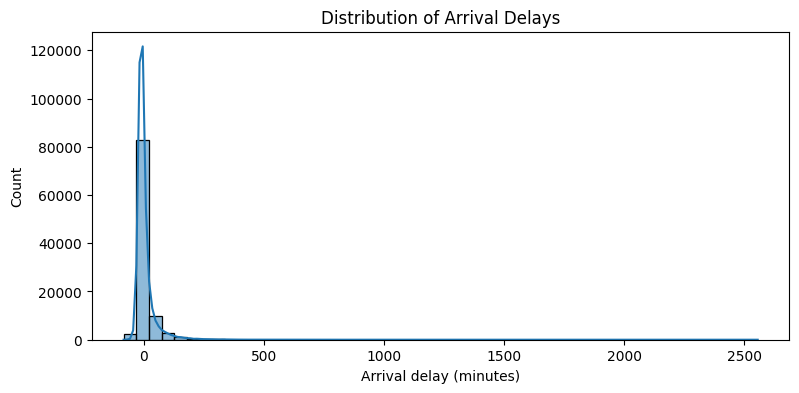

In [25]:
plt.figure(figsize=(9, 4))
sns.histplot(df_clean["ARR_DELAY"].dropna().sample(
    min(100_000, df_clean["ARR_DELAY"].notna().sum()), random_state=42
), bins=50, kde=True)
plt.xlabel("Arrival delay (minutes)")
plt.title("Distribution of Arrival Delays")
plt.show()

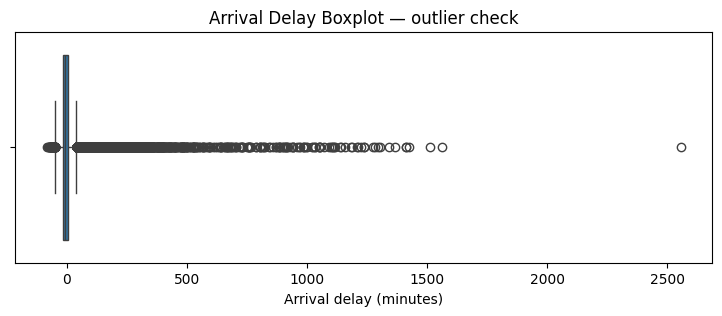

In [26]:
plt.figure(figsize=(9, 3))
sns.boxplot(x=df_clean["ARR_DELAY"].dropna().sample(
    min(100_000, df_clean["ARR_DELAY"].notna().sum()), random_state=42
))
plt.xlabel("Arrival delay (minutes)")
plt.title("Arrival Delay Boxplot — outlier check")
plt.show()

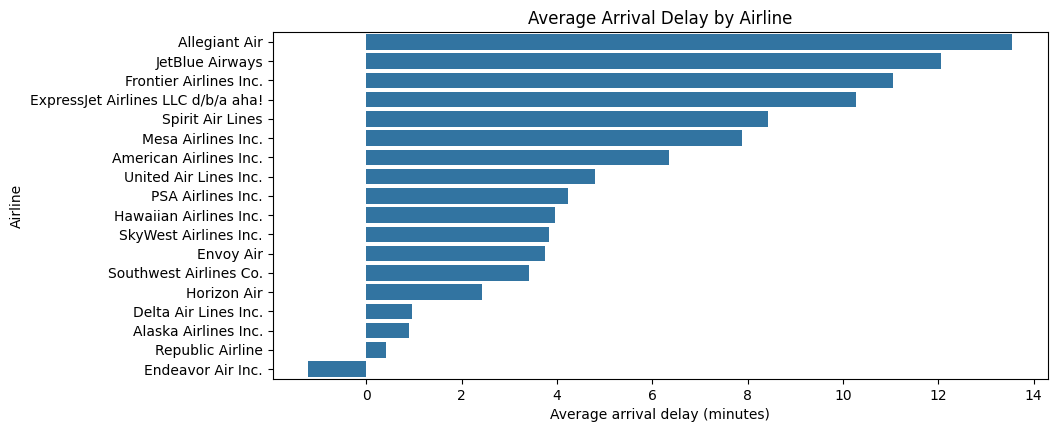

In [27]:
airline_delay = df_clean.groupby("AIRLINE")["ARR_DELAY"].mean().sort_values(ascending=False)
plt.figure(figsize=(10, max(4, len(airline_delay) * 0.25)))
sns.barplot(x=airline_delay.values, y=airline_delay.index)
plt.xlabel("Average arrival delay (minutes)")
plt.ylabel("Airline")
plt.title("Average Arrival Delay by Airline")
plt.show()

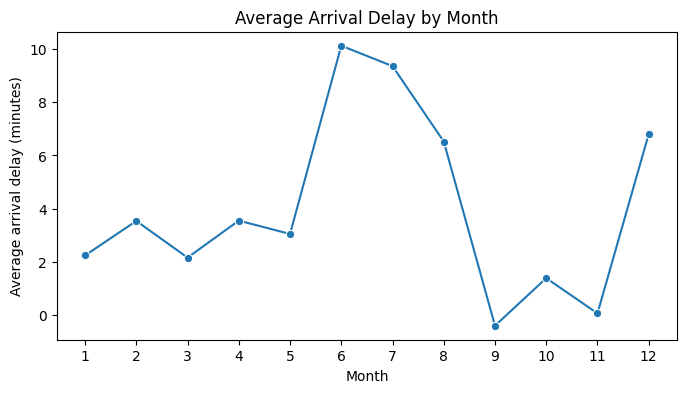

In [28]:
monthly_delay = df_clean.groupby("MONTH")["ARR_DELAY"].mean()
plt.figure(figsize=(8, 4))
sns.lineplot(x=monthly_delay.index, y=monthly_delay.values, marker="o")
plt.xlabel("Month")
plt.ylabel("Average arrival delay (minutes)")
plt.title("Average Arrival Delay by Month")
plt.xticks(range(1, 13))
plt.show()

In [29]:
df_prob = df_clean.copy()
df_prob["IS_DELAYED_15"] = (df_prob["ARR_DELAY"] > 15).astype(int)

In [30]:
p_delayed = df_prob["IS_DELAYED_15"].mean()
print(f"P(arrival delay > 15 min) = {p_delayed:.4f}")

P(arrival delay > 15 min) = 0.1775


In [31]:
weather_col = "DELAY_DUE_WEATHER"
if weather_col in df_prob.columns:
    weather_delayed = df_prob[df_prob[weather_col] > 0]
    if len(weather_delayed):
        conditional_p = (weather_delayed["ARR_DELAY"] > 15).mean()
        print(f"P(arrival delay > 15 | weather delay recorded) = {conditional_p:.4f}")
    else:
        print("No rows with a positive weather-delay value.")
else:
    print("Weather delay column not available; conditional probability skipped.")

P(arrival delay > 15 | weather delay recorded) = 0.9860


In [32]:
sample_n = min(5000, len(df_prob))
flight_sample = df_prob.sample(n=sample_n, random_state=42)
print("Random sample shape:", flight_sample.shape)

Random sample shape: (5000, 35)


In [33]:
display(flight_sample[["ARR_DELAY", "IS_DELAYED_15"]].head())

,ARR_DELAY,IS_DELAYED_15
490648,216.0,1
640821,-13.0,0
566939,-24.0,0
263433,0.0,0
210055,-15.0,0


In [34]:
rng = np.random.default_rng(42)
arr = df_clean["ARR_DELAY"].dropna().to_numpy()
sample_size = min(500, len(arr))
n_repetitions = 500

In [35]:
sample_means = [
    rng.choice(arr, size=sample_size, replace=True).mean()
    for _ in range(n_repetitions)
]

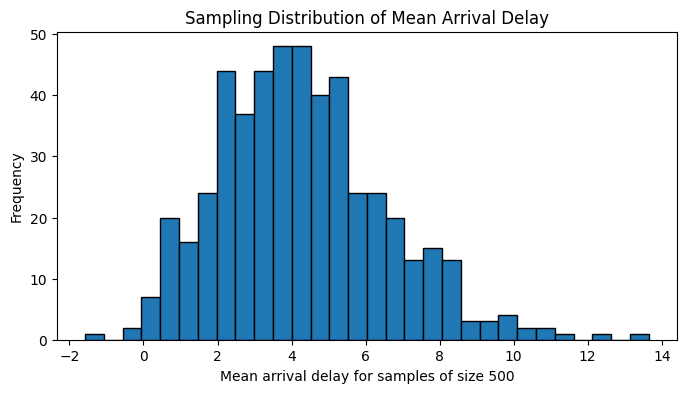

In [36]:
plt.figure(figsize=(8, 4))
plt.hist(sample_means, bins=30, edgecolor="black")
plt.xlabel(f"Mean arrival delay for samples of size {sample_size}")
plt.ylabel("Frequency")
plt.title("Sampling Distribution of Mean Arrival Delay")
plt.show()

In [37]:
print("Mean of sample means:", np.mean(sample_means))
print("Original population-data mean (available dataset):", np.mean(arr))

Mean of sample means: 4.274812
Original population-data mean (available dataset): 4.226696163619781


In [38]:
arr = df_clean["ARR_DELAY"].dropna().to_numpy()
n = len(arr)
sample_mean = np.mean(arr)
sample_std = np.std(arr, ddof=1)
standard_error = sample_std / np.sqrt(n)

In [39]:
confidence = 0.95
t_critical = stats.t.ppf((1 + confidence) / 2, df=n - 1)
ci_lower = sample_mean - t_critical * standard_error
ci_upper = sample_mean + t_critical * standard_error

In [40]:
print(f"Mean arrival delay: {sample_mean:.3f} minutes")
print(f"Median arrival delay: {np.median(arr):.3f} minutes")
print(f"95% t confidence interval for mean: ({ci_lower:.3f}, {ci_upper:.3f})")

Mean arrival delay: 4.227 minutes
Median arrival delay: -7.000 minutes
95% t confidence interval for mean: (4.104, 4.350)


In [41]:
rng = np.random.default_rng(42)
boot_source = rng.choice(arr, size=min(len(arr), 50_000), replace=False)
boot_medians = [
    np.median(rng.choice(boot_source, size=len(boot_source), replace=True))
    for _ in range(300)
]
boot_ci = np.percentile(boot_medians, [2.5, 97.5])
print(f"Bootstrap 95% CI for median: ({boot_ci[0]:.3f}, {boot_ci[1]:.3f})")

Bootstrap 95% CI for median: (-7.000, -7.000)


In [42]:
arr_sample = df_clean["ARR_DELAY"].dropna()
t_stat, p_value_t = stats.ttest_1samp(arr_sample, popmean=1)

In [43]:
print("One-sample t-statistic:", t_stat)
print("p-value:", p_value_t)

One-sample t-statistic: 51.464806807807875
p-value: 0.0


In [44]:
alpha = 0.05
if p_value_t < alpha:
    print("Reject H0: mean arrival delay differs significantly from zero.")
else:
    print("Fail to reject H0: insufficient evidence that mean arrival delay differs from zero.")

Reject H0: mean arrival delay differs significantly from zero.


In [45]:
sigma_population = arr_sample.std(ddof=1)
z_score = (arr_sample.mean() - 0) / (sigma_population / np.sqrt(len(arr_sample)))
p_value_z = 2 * (1 - stats.norm.cdf(abs(z_score)))

In [46]:
print("Illustrative Z-score:", z_score)
print("Illustrative two-sided Z p-value:", p_value_z)

Illustrative Z-score: 67.41449782242424
Illustrative two-sided Z p-value: 0.0


In [47]:
alpha = 0.05
if p_value_t < alpha:
    print("Reject H0: mean arrival delay differs significantly from zero.")
else:
    print("Fail to reject H0: insufficient evidence that mean arrival delay differs from zero.")

Reject H0: mean arrival delay differs significantly from zero.


In [48]:
sigma_population = arr_sample.std(ddof=1)
z_score = (arr_sample.mean() - 0) / (sigma_population / np.sqrt(len(arr_sample)))
p_value_z = 2 * (1 - stats.norm.cdf(abs(z_score)))

In [49]:
print("Illustrative Z-score:", z_score)
print("Illustrative two-sided Z p-value:", p_value_z)

Illustrative Z-score: 67.41449782242424
Illustrative two-sided Z p-value: 0.0


In [50]:
weekday = df_clean.loc[df_clean["DAY_OF_WEEK"].between(1, 5), "ARR_DELAY"].dropna()
weekend = df_clean.loc[df_clean["DAY_OF_WEEK"].isin([6, 7]), "ARR_DELAY"].dropna()
t_stat, p_value = stats.ttest_ind(weekday, weekend, equal_var=False)

In [51]:
print("Weekday mean delay:", weekday.mean())
print("Weekend mean delay:", weekend.mean())
print("Welch t-statistic:", t_stat)
print("p-value:", p_value)

Weekday mean delay: 4.1065235896726255
Weekend mean delay: 4.545391865217271
Welch t-statistic: -3.053600339924086
p-value: 0.0022613223549021585


In [52]:
if p_value < 0.05:
  print("Reject H0: average arrival delays differ between weekday and weekend flights.")
else:
  print("Fail to reject H0: insufficient evidence of a difference.")

Reject H0: average arrival delays differ between weekday and weekend flights.


In [53]:
paired = df_clean[["DEP_DELAY", "ARR_DELAY"]].dropna()
paired = paired.sample(min(100_000, len(paired)), random_state=42)
t_stat, p_value = stats.ttest_rel(paired["DEP_DELAY"], paired["ARR_DELAY"])

In [54]:
print("Mean departure delay:", paired["DEP_DELAY"].mean())
print("Mean arrival delay:", paired["ARR_DELAY"].mean())
print("Paired t-statistic:", t_stat)
print("p-value:", p_value)

Mean departure delay: 10.08636
Mean arrival delay: 4.35005
Paired t-statistic: 134.68544384637926
p-value: 0.0


In [55]:
top_airlines = df_clean["AIRLINE"].value_counts().head(5).index
groups = [
  df_clean.loc[df_clean["AIRLINE"] == airline, "ARR_DELAY"].dropna().sample(
  min(20_000, (df_clean["AIRLINE"] == airline).sum()), random_state=42
  )
  for airline in top_airlines
]
groups = [g for g in groups if len(g) > 1]
if len(groups) >= 2:
  f_stat, p_value = stats.f_oneway(*groups)
  print("Airlines compared:", list(top_airlines))
  print("ANOVA F-statistic:", f_stat)
  print("p-value:", p_value)
  print("Reject H0: at least one group mean differs." if p_value < 0.05
else "Fail to reject H0: insufficient evidence of different means.")

Airlines compared: ['Southwest Airlines Co.', 'Delta Air Lines Inc.', 'American Airlines Inc.', 'SkyWest Airlines Inc.', 'United Air Lines Inc.']
ANOVA F-statistic: 33.69292138328386
p-value: 3.8796638837861126e-28
Reject H0: at least one group mean differs.


In [56]:
top_airlines = df_prob["AIRLINE"].value_counts().head(8).index
chi_data = df_prob[df_prob["AIRLINE"].isin(top_airlines)].copy()
chi_data["Delay_Status"] = np.where(chi_data["ARR_DELAY"] > 15, "Delayed", "Not delayed")
contingency = pd.crosstab(chi_data["AIRLINE"], chi_data["Delay_Status"])
display(contingency)

Delay_Status,Delayed,Not delayed
AIRLINE,,
American Airlines Inc.,16114,67087
Delta Air Lines Inc.,12177,75757
Endeavor Air Inc.,3131,21747
Envoy Air,4503,22194
Republic Airline,4705,26364
SkyWest Airlines Inc.,11596,63696
Southwest Airlines Co.,23465,101444
United Air Lines Inc.,10330,45941


In [57]:
chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p_value)
print("Reject H0: airline and delay status are associated." if p_value < 0.05
else "Fail to reject H0: insufficient evidence of association.")

Chi-square statistic: 1866.8353266358058
Degrees of freedom: 7
p-value: 0.0
Reject H0: airline and delay status are associated.


In [58]:
corr_df = df_clean[["DEP_DELAY", "ARR_DELAY"]].dropna()
corr_df = corr_df.sample(min(100_000, len(corr_df)), random_state=42)

In [59]:
covariance = corr_df["DEP_DELAY"].cov(corr_df["ARR_DELAY"])
pearson_r, pearson_p = stats.pearsonr(corr_df["DEP_DELAY"], corr_df["ARR_DELAY"])
spearman_rho, spearman_p = stats.spearmanr(corr_df["DEP_DELAY"], corr_df["ARR_DELAY"])

In [60]:
print("Covariance:", covariance)
print("Pearson r:", pearson_r, "| p-value:", pearson_p)
print("Spearman rho:", spearman_rho, "| p-value:", spearman_p)

Covariance: 2485.865578337785
Pearson r: 0.9656244223212529 | p-value: 0.0
Spearman rho: 0.6574755587835293 | p-value: 0.0


In [61]:
if abs(pearson_r) >= 0.7:
  print("Pearson interpretation: strong linear relationship")
elif abs(pearson_r) >= 0.4:
  print("Pearson interpretation: moderate linear relationship")
else:
  print("Pearson interpretation: weak linear relationship")

Pearson interpretation: strong linear relationship


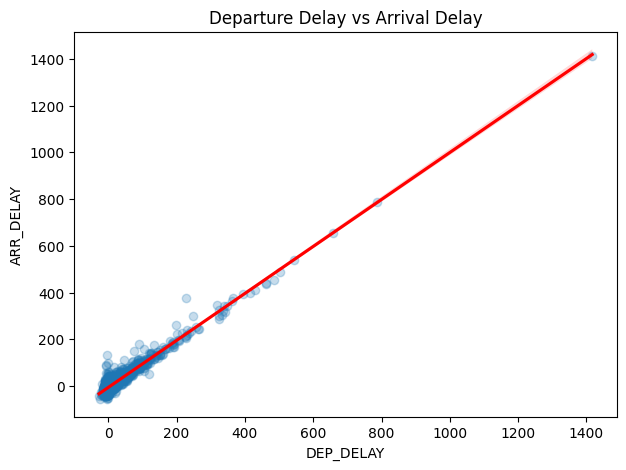

In [62]:
plt.figure(figsize=(7, 5))
sns.regplot(data=corr_df.sample(min(3000, len(corr_df)), random_state=42), x="DEP_DELAY", y="ARR_DELAY", scatter_kws={"alpha": 0.25}, line_kws={"color": "red"})
plt.title("Departure Delay vs Arrival Delay")
plt.show()

In [63]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib
import time

In [64]:
target = "ARR_DELAY"
candidate_features = ["DEP_DELAY", "AIR_TIME", "DISTANCE", "MONTH", "DAY_OF_WEEK", "AIRLINE", "ORIGIN", "DEST"]
features = []
for col in candidate_features:
    if col in df_clean.columns:
        features.append(col)
print("Features:", features)

Features: ['DEP_DELAY', 'AIR_TIME', 'DISTANCE', 'MONTH', 'DAY_OF_WEEK', 'AIRLINE', 'ORIGIN', 'DEST']


In [65]:
model_df = df_clean[features + [target]].dropna(subset=[target]).copy()
model_df = model_df.sample(n=min(30000, len(model_df)), random_state=42)
X = model_df[features]
y = model_df[target]
print("Rows used for modelling:", len(model_df))

Rows used for modelling: 30000


In [66]:
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_features = []
for col in features:
    if col not in categorical_features:
        numerical_features.append(col)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [67]:
num_imputer = SimpleImputer(strategy="median")
X_train_num = num_imputer.fit_transform(X_train[numerical_features])
X_test_num = num_imputer.transform(X_test[numerical_features])

In [68]:
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train_num)
X_test_num = scaler.transform(X_test_num)

In [69]:
cat_imputer = SimpleImputer(strategy="most_frequent")
X_train_cat = cat_imputer.fit_transform(X_train[categorical_features])
X_test_cat = cat_imputer.transform(X_test[categorical_features])

In [70]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown="ignore", min_frequency=20)
X_train_cat = encoder.fit_transform(X_train_cat)
X_test_cat = encoder.transform(X_test_cat)

In [72]:
from scipy.sparse import csr_matrix, hstack
X_train_final = hstack([csr_matrix(X_train_num), X_train_cat])
X_test_final = hstack([csr_matrix(X_test_num), X_test_cat])

In [73]:
print("Training data shape:", X_train_final.shape)
print("Testing data shape:", X_test_final.shape)

Training data shape: (24000, 302)
Testing data shape: (6000, 302)


In [74]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.01, max_iter=3000),
    "Decision Tree": DecisionTreeRegressor(max_depth=18, min_samples_leaf=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=18, min_samples_leaf=3, random_state=42, n_jobs=-1)
}

In [75]:
results = []
trained_models = {}

In [76]:
for name, current_model in models.items():
    start_time = time.time()
    current_model.fit(X_train_final, y_train)
    train_time = time.time() - start_time
    predictions = current_model.predict(X_test_final)
    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)
    results.append([name, mae, mse, rmse, r2, train_time])
    trained_models[name] = current_model

In [77]:
comparison_table = pd.DataFrame(results, columns=["Model", "MAE", "MSE", "RMSE", "R2 Score", "Training Time (seconds)"])
comparison_table = comparison_table.sort_values("RMSE").reset_index(drop=True)
display(comparison_table.round(4))

,Model,MAE,MSE,RMSE,R2 Score,Training Time (seconds)
0,Ridge,8.0356,133.3724,11.5487,0.9537,0.1396
1,Linear Regression,8.0379,133.4068,11.5502,0.9537,0.2065
2,Lasso,8.3268,141.7457,11.9057,0.9508,9.4616
3,Random Forest,9.0972,166.6861,12.9107,0.9421,67.1838
4,Decision Tree,10.2847,214.1206,14.6329,0.9257,0.8468


In [78]:
best_name = comparison_table.loc[0, "Model"]
best_model = trained_models[best_name]
print("Best model based on lowest RMSE:", best_name)

Best model based on lowest RMSE: Ridge


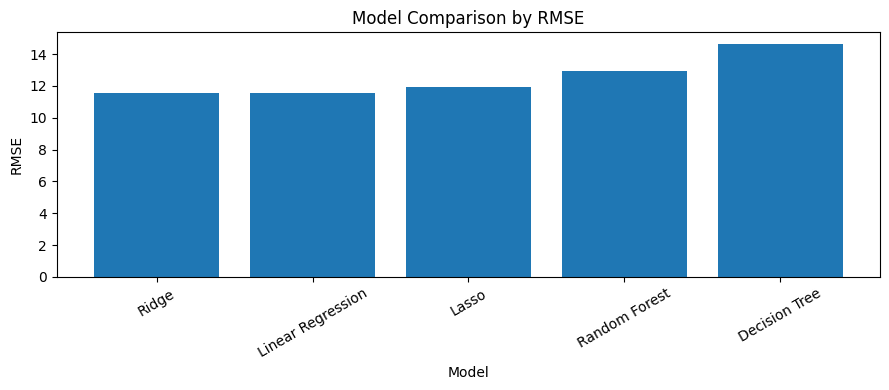

In [79]:
plt.figure(figsize=(9, 4))
plt.bar(comparison_table["Model"], comparison_table["RMSE"])
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("Model Comparison by RMSE")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns

In [84]:
plot_df = comparison_table.sort_values("RMSE", ascending=True).copy()
colors = ['#2ca02c' if name == best_name else '#1f77b4' for name in plot_df["Model"]]

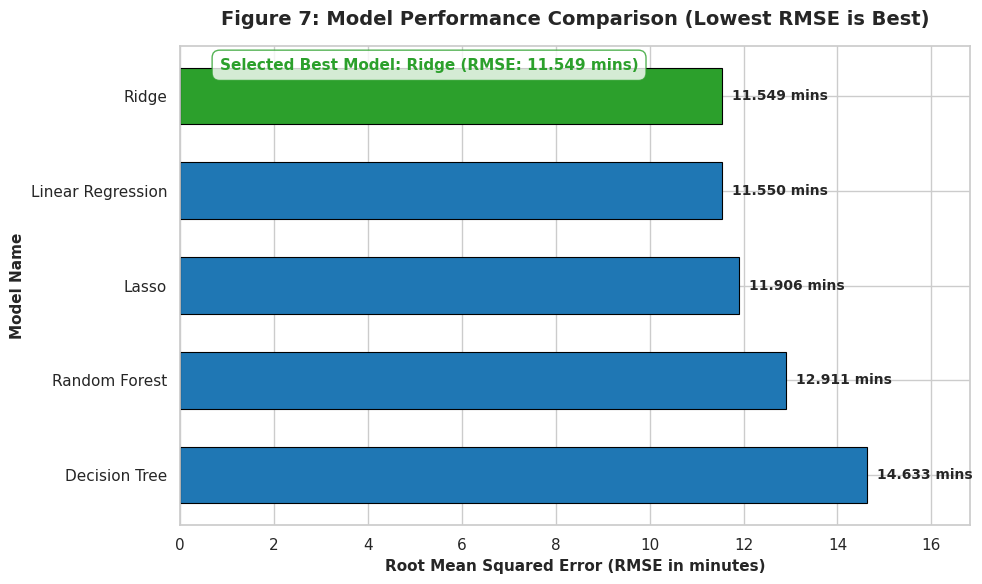

In [85]:
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
bars = plt.barh(plot_df["Model"], plot_df["RMSE"], color=colors, height=0.6, edgecolor='black', linewidth=0.8)
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.2, bar.get_y() + bar.get_height()/2, f'{width:.3f} mins',
             va='center', ha='left', fontweight='bold', fontsize=10)
plt.xlim(0, max(plot_df["RMSE"]) * 1.15)
plt.xlabel("Root Mean Squared Error (RMSE in minutes)", fontsize=11, fontweight='bold')
plt.ylabel("Model Name", fontsize=11, fontweight='bold')
plt.title("Figure 7: Model Performance Comparison (Lowest RMSE is Best)", fontsize=14, fontweight='bold', pad=15)
plt.text(0.05, 0.95, f"Selected Best Model: {best_name} (RMSE: {plot_df.loc[plot_df['Model'] == best_name, 'RMSE'].values[0]:.3f} mins)",
         transform=plt.gca().transAxes, fontsize=11, fontweight='bold', color='#2ca02c',
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='#2ca02c', boxstyle='round,pad=0.5'))
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [80]:
joblib.dump(best_model, "flight_delay_best_model.joblib")
joblib.dump(num_imputer, "numeric_imputer.joblib")
joblib.dump(scaler, "numeric_scaler.joblib")
joblib.dump(cat_imputer, "categorical_imputer.joblib")
joblib.dump(encoder, "onehot_encoder.joblib")
print("Saved best model:", best_name)

Saved best model: Ridge
